In [1]:
from __future__ import division
import matplotlib.pyplot as plt
from deltasigma import *
import numpy as np
from IPython.core.display import Image
import numpy as np, pandas as pd

#from turtle import title
from matplotlib import text

In [2]:
def readSamples(fileName):
    samples = []
    inFile = open(fileName, "r")
    for line in inFile:
        samples.append( complex(line) )
    return np.array(samples)

In [3]:
N    = 65536
BITS = 16
FS_Q = 15.0
OSR  = 8
AMP  = 0.5    

In [4]:
fB    = int(np.ceil(N/(2.*OSR)))
ftest = int(np.floor(2./7*fB))

print(f"fB = {fB},  ftest = {ftest},  f_in = {ftest/N:.6f}*fs")

fB = 4096,  ftest = 1170,  f_in = 0.017853*fs


In [5]:
def gen_sine(amp, fname="Podaci", N=N, ftest=ftest, bits=BITS, fs_q=FS_Q):
    n   = np.arange(N)
    s = np.sin(2*np.pi*ftest*n/N)
    x = amp * fs_q * s
    np.savetxt(fname, x, fmt="%.17g")
    return x

x = gen_sine(AMP)

/home/paki/miniconda3/envs/ds/lib/python3.7/site-packages/ipykernel_launcher.py:17: RuntimeWarning: divide by zero encountered in double_scalars
  app.launch_new_instance()


SNR  = inf dB
ENOB = inf bita


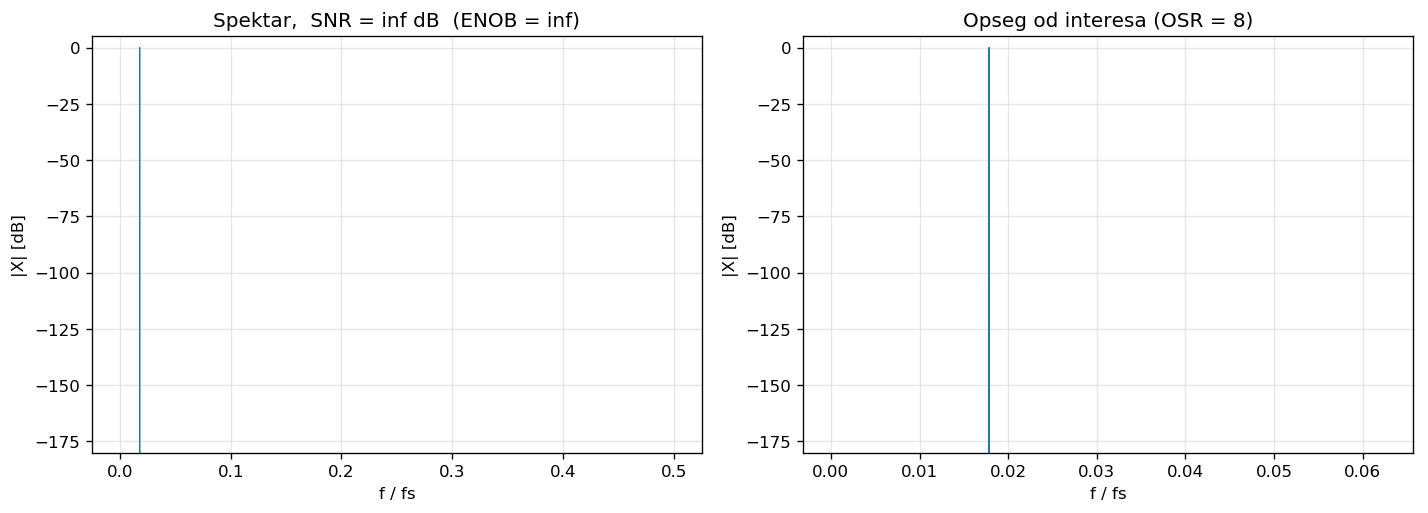

srednji nivo po binu: -36.1 dB
maksimum po binu:     0.0 dB
+10log10(bw) = 36.1 dB  ->  SNR = inf dB
10·log10(2048) ≈ 33 dB  ->  SNR = inf dB


In [6]:
podaci = readSamples("Podaci")

x  = np.real(podaci)                     
Nx = len(x)
# x  = x - np.mean(x)                       

X = np.fft.fft(x) / (Nx/2)               
P = np.abs(X[:Nx//2])**2      

f = np.arange(Nx//2) / Nx                

bw = Nx // (2*OSR)                        # poslednji bin opsega od interesa
k  = 1 + np.argmax(P[1:bw])               # bin signala

sig   = P[k]
noise = P[1:bw].sum() - sig
snr   = 10*np.log10(sig/noise)
enob  = (snr - 1.76) / 6.02

print(f"SNR  = {snr:.1f} dB")
print(f"ENOB = {enob:.2f} bita")

XdB = 10*np.log10(P + 1e-300); XdB -= XdB.max()

fig = plt.figure(figsize=(12, 8), dpi=120)

plt.subplot(2, 2, 1)
plt.plot(f, XdB, lw=0.7)
plt.xlabel('f / fs'); plt.ylabel('|X| [dB]')
plt.ylim(-180, 5); plt.grid(True, alpha=.3)
plt.title(f'Spektar,  SNR = {snr:.1f} dB  (ENOB = {enob:.2f})')

plt.subplot(2, 2, 2)
plt.plot(f[:bw], XdB[:bw], lw=0.8)
plt.xlabel('f / fs'); plt.ylabel('|X| [dB]')
plt.ylim(-180, 5); plt.grid(True, alpha=.3)
plt.title(f'Opseg od interesa (OSR = {OSR})')

plt.tight_layout(); plt.show()

print(f"srednji nivo po binu: {10*np.log10(P[1:bw].mean()/P[k]):.1f} dB")
print(f"maksimum po binu:     {10*np.log10(P[1:bw].max()/P[k]):.1f} dB")
print(f"+10log10(bw) = {10*np.log10(bw):.1f} dB  ->  SNR = {snr:.1f} dB")

print(f"10·log10(2048) ≈ 33 dB  ->  SNR = {snr:.1f} dB")

In [7]:
DELTA = 2.0                       # korak kvantizatora (neparne vrednosti)
A     = AMP * FS_Q                # stvarna amplituda sinusoide

Ps = A**2 / 2                     # snaga sinusoide
Pn = DELTA**2 / 12                # snaga kvantizacionog suma (beli, ravan)

sqnr_nyq = 10*np.log10(Ps/Pn)                     # ravan DAC, bez preodabiranja
sqnr_os  = sqnr_nyq + 10*np.log10(OSR)            # + dobitak preodabiranja
L        = 5                                      # red modulatora
sqnr_dsm = sqnr_nyq + 10*np.log10((2*L+1)/np.pi**(2*L) * OSR**(2*L+1))

print(f"ravan DAC ({DELTA:.0f} LSB, A={A:.1f}):      {sqnr_nyq:6.1f} dB")
print(f"+ preodabiranje (OSR={OSR}):          {sqnr_os:6.1f} dB")
print(f"+ noise shaping {L}. reda (teorija):  {sqnr_dsm:6.1f} dB")
print(f"izmereno:                            {snr:6.1f} dB")

ravan DAC (2 LSB, A=7.5):        19.3 dB
+ preodabiranje (OSR=8):            28.3 dB
+ noise shaping 5. reda (teorija):    79.3 dB
izmereno:                               inf dB


In [8]:
DELTA = 2.0                                          # korak tvog kvantizatora
rng   = np.random.default_rng(12345)

podaci_dac = np.real(podaci) + rng.uniform(-DELTA/2, DELTA/2, len(podaci))

SQNR pri punoj skali	6.02·4 + 1.76 = 25.8 dB //

SQNR pri AMP = 0.5 (A = 7.5)	19.3 dB //

isto, u opsegu do fs/32 (OSR = 16)	19.3 + 12.0 = 31.3 dB //

SNR  = 28.3 dB
ENOB = 4.41 bita


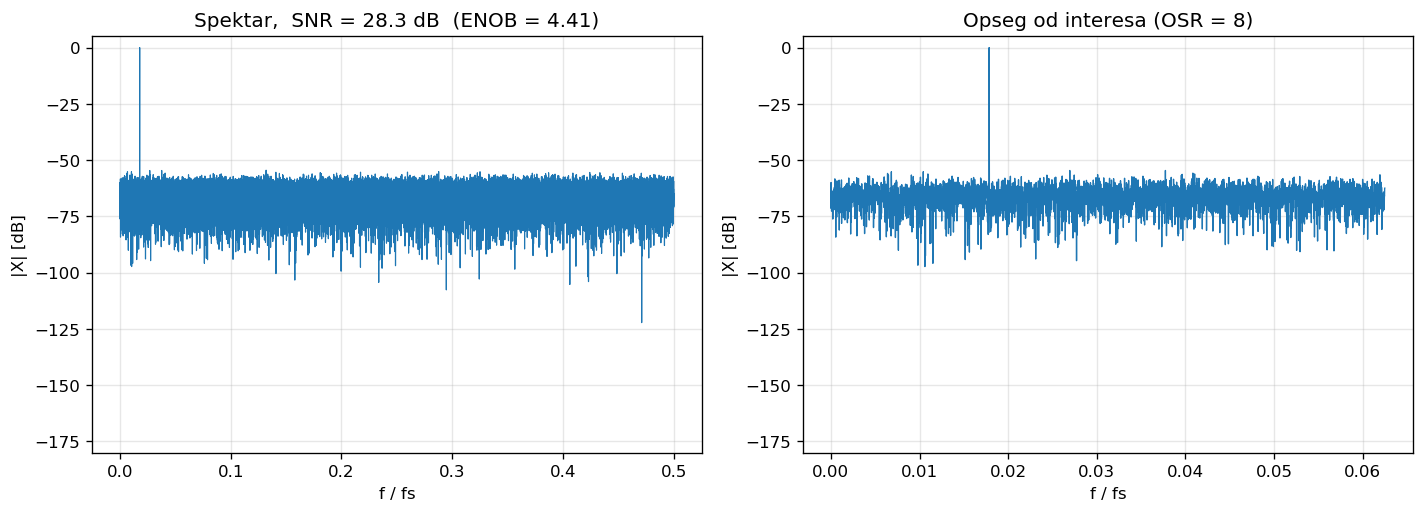

srednji nivo po binu: -36.1 dB
maksimum po binu:     0.0 dB
+10log10(bw) = 36.1 dB  ->  SNR = 28.3 dB
10·log10(2048) ≈ 33 dB  ->  SNR = 28.3 dB


In [9]:
x  = np.real(podaci_dac)                     
Nx = len(x)
# x  = x - np.mean(x)                       

X = np.fft.fft(x) / (Nx/2)               
P = np.abs(X[:Nx//2])**2      

f = np.arange(Nx//2) / Nx                

bw = Nx // (2*OSR)                        # poslednji bin opsega od interesa
k  = 1 + np.argmax(P[1:bw])               # bin signala

sig   = P[k]
noise = P[1:bw].sum() - sig
snr   = 10*np.log10(sig/noise)
enob  = (snr - 1.76) / 6.02

print(f"SNR  = {snr:.1f} dB")
print(f"ENOB = {enob:.2f} bita")

XdB = 10*np.log10(P + 1e-300); XdB -= XdB.max()

fig = plt.figure(figsize=(12, 8), dpi=120)

plt.subplot(2, 2, 1)
plt.plot(f, XdB, lw=0.7)
plt.xlabel('f / fs'); plt.ylabel('|X| [dB]')
plt.ylim(-180, 5); plt.grid(True, alpha=.3)
plt.title(f'Spektar,  SNR = {snr:.1f} dB  (ENOB = {enob:.2f})')

plt.subplot(2, 2, 2)
plt.plot(f[:bw], XdB[:bw], lw=0.8)
plt.xlabel('f / fs'); plt.ylabel('|X| [dB]')
plt.ylim(-180, 5); plt.grid(True, alpha=.3)
plt.title(f'Opseg od interesa (OSR = {OSR})')

plt.tight_layout(); plt.show()

print(f"srednji nivo po binu: {10*np.log10(P[1:bw].mean()/P[k]):.1f} dB")
print(f"maksimum po binu:     {10*np.log10(P[1:bw].max()/P[k]):.1f} dB")
print(f"+10log10(bw) = {10*np.log10(bw):.1f} dB  ->  SNR = {snr:.1f} dB")

print(f"10·log10(2048) ≈ 33 dB  ->  SNR = {snr:.1f} dB")

# IZLAZ


## CRFBD IDEAL

Text(0,0.5,'dBFS')

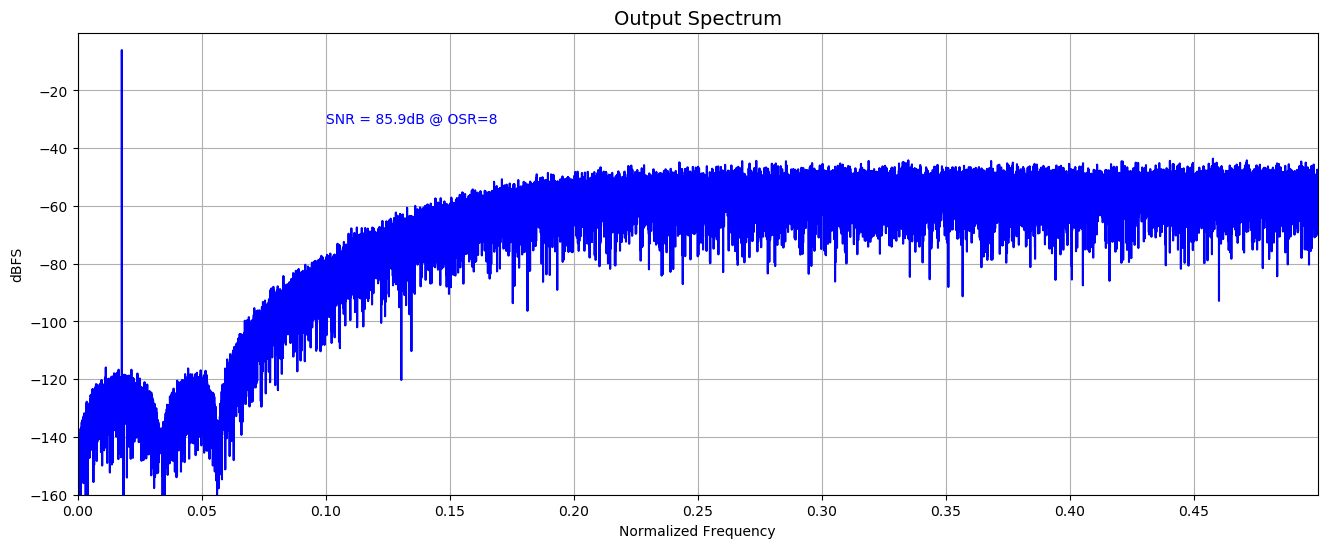

In [10]:
obradjeni_ideal = readSamples("../cpp/Obradjeni_ideal")

v_ideal  = np.real(obradjeni_ideal)

f = np.linspace(0, 0.5, N//2 + 1)
spec_ideal = np.fft.fft(v_ideal*ds_hann(N))/(int(FS_Q)*N/4)
plt.plot(f, dbv(spec_ideal[:N//2 + 1]), 'b', label='Simulation')
snr = calculateSNR(spec_ideal[2:fB + 1], ftest - 2)
plt.text(0.1, 10*(1 - 4), 'SNR = %4.1fdB @ OSR=%d' % (snr, OSR), verticalalignment='center', color='b')
figureMagic([0, 0.5], 0.05, None, [-160, 0], 20, None, (16, 6), 'Output Spectrum')
plt.xlabel('Normalized Frequency')
plt.ylabel('dBFS')

## CRFBD REAL

Text(0,0.5,'dBFS')

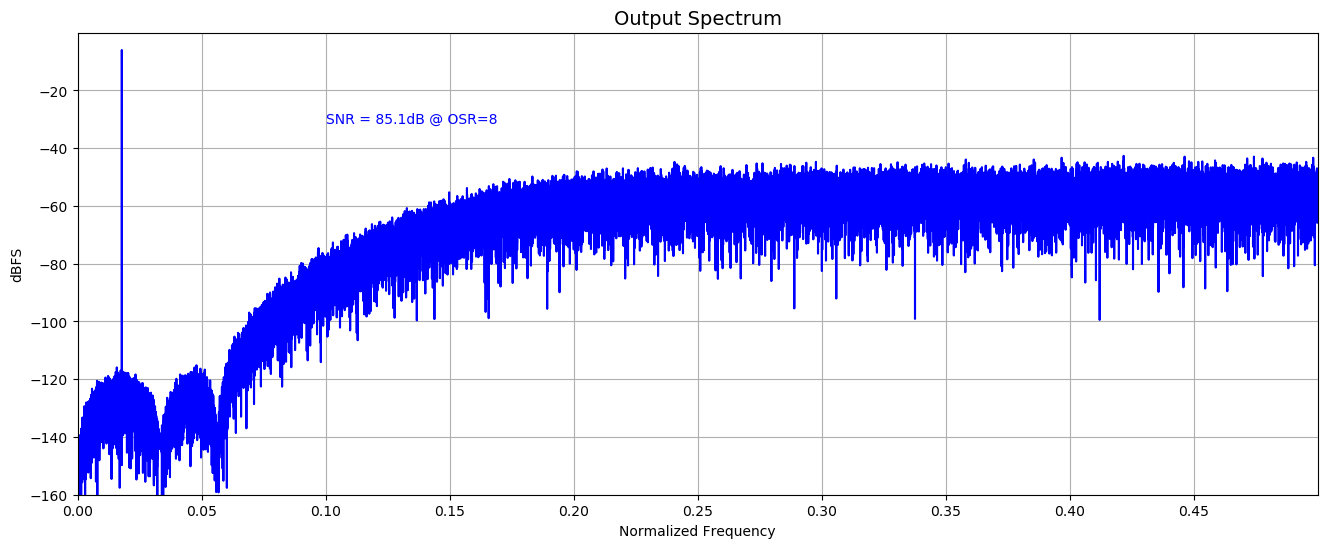

In [11]:
obradjeni_real = readSamples("../cpp/Obradjeni_real")

v_real = np.real(obradjeni_real)

f = np.linspace(0, 0.5, N//2 + 1)
spec_real = np.fft.fft(v_real*ds_hann(N))/(int(FS_Q)*N/4)
plt.plot(f, dbv(spec_real[:N//2 + 1]), 'b', label='Simulation')
snr = calculateSNR(spec_real[2:fB + 1], ftest - 2)
plt.text(0.1, 10*(1 - 4), 'SNR = %4.1fdB @ OSR=%d' % (snr, OSR), verticalalignment='center', color='b')
figureMagic([0, 0.5], 0.05, None, [-160, 0], 20, None, (16, 6), 'Output Spectrum')
plt.xlabel('Normalized Frequency')
plt.ylabel('dBFS')

## MASH IDEAL

Text(0,0.5,'dBFS')

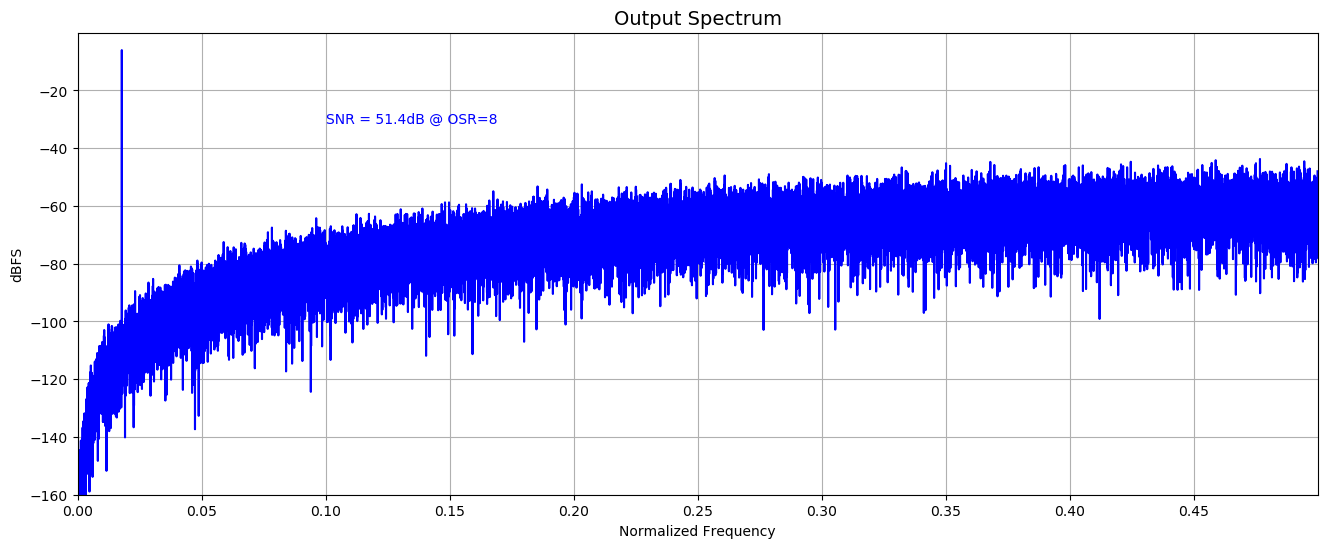

In [12]:
obradjeni_mash = readSamples("../cpp/Obradjeni_mash")

v_real = np.real(obradjeni_mash)

f = np.linspace(0, 0.5, N//2 + 1)
spec_real = np.fft.fft(v_real*ds_hann(N))/(int(FS_Q)*N/4)
plt.plot(f, dbv(spec_real[:N//2 + 1]), 'b', label='Simulation')
snr = calculateSNR(spec_real[2:fB + 1], ftest - 2)
plt.text(0.1, 10*(1 - 4), 'SNR = %4.1fdB @ OSR=%d' % (snr, OSR), verticalalignment='center', color='b')
figureMagic([0, 0.5], 0.05, None, [-160, 0], 20, None, (16, 6), 'Output Spectrum')
plt.xlabel('Normalized Frequency')
plt.ylabel('dBFS')

## MASH REAL

Text(0,0.5,'dBFS')

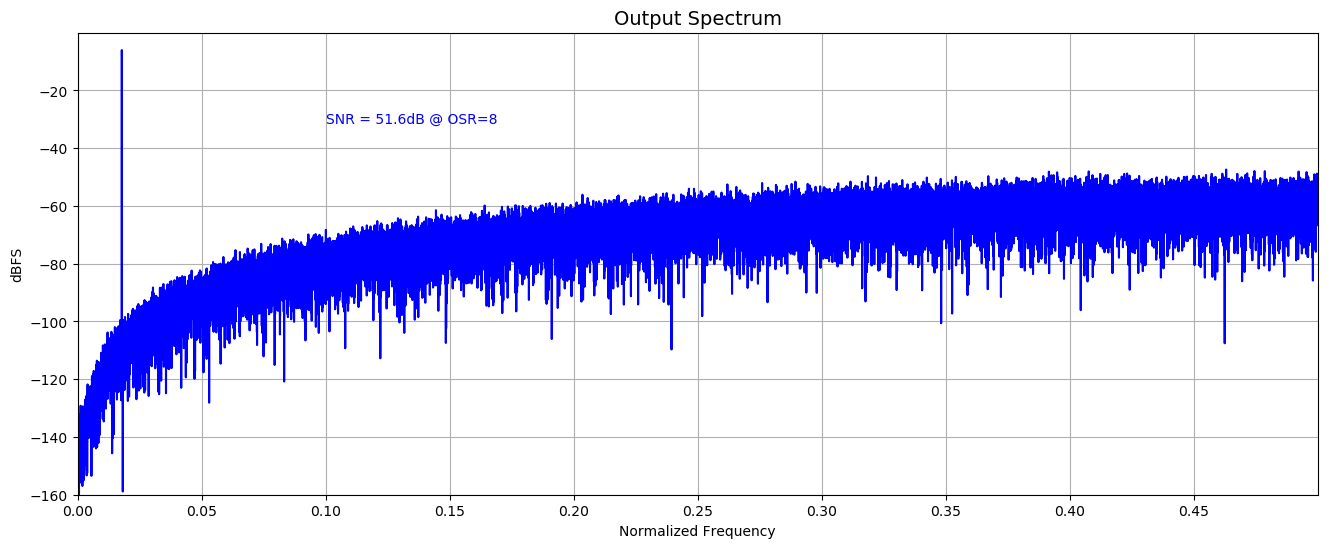

In [5]:
obradjeni_mash = readSamples("../cpp/Obradjeni_mash_real")

v_real = np.real(obradjeni_mash)

f = np.linspace(0, 0.5, N//2 + 1)
spec_real = np.fft.fft(v_real*ds_hann(N))/(int(FS_Q)*N/4)
plt.plot(f, dbv(spec_real[:N//2 + 1]), 'b', label='Simulation')
snr = calculateSNR(spec_real[2:fB + 1], ftest - 2)
plt.text(0.1, 10*(1 - 4), 'SNR = %4.1fdB @ OSR=%d' % (snr, OSR), verticalalignment='center', color='b')
figureMagic([0, 0.5], 0.05, None, [-160, 0], 20, None, (16, 6), 'Output Spectrum')
plt.xlabel('Normalized Frequency')
plt.ylabel('dBFS')

## MASH VHD

Text(0,0.5,'dBFS')

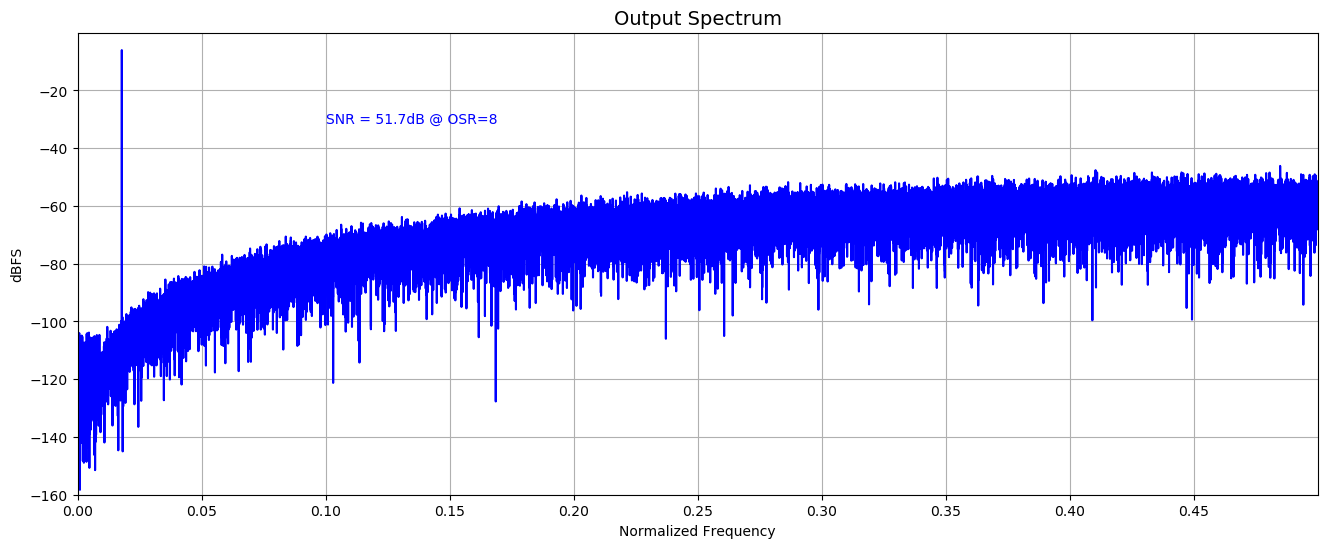

In [7]:
obradjeni_vhd = readSamples("../hdl/Obradjeni")

v_vhd = np.real(obradjeni_vhd)

f = np.linspace(0, 0.5, N//2 + 1)
spec_real = np.fft.fft(v_vhd*ds_hann(N))/(int(FS_Q)*N/4)
plt.plot(f, dbv(spec_real[:N//2 + 1]), 'b', label='Simulation')
snr = calculateSNR(spec_real[2:fB + 1], ftest - 2)
plt.text(0.1, 10*(1 - 4), 'SNR = %4.1fdB @ OSR=%d' % (snr, OSR), verticalalignment='center', color='b')
figureMagic([0, 0.5], 0.05, None, [-160, 0], 20, None, (16, 6), 'Output Spectrum')
plt.xlabel('Normalized Frequency')
plt.ylabel('dBFS')